# NB5c conformal — calibrated intervals for PVSetFormer (validation units only)

D06, D35, D45. Rule R1 chose PVSetFormer as the main index forecaster (`results/nb5c_r1/`, configuration part 2c). The conformal layer of D35 was built for LightGBM; this notebook applies **the same rules, unchanged**, to PVSetFormer's 5-seed ensemble. Reads `results/nb5c_r1/` and the final variant's folder in `results/nb5c_variants/`; writes `results/nb5c_conformal/`. No test event is used.

**Rules (D35, fixed before any number below):**
1. *Calibration set*, per event, origin and horizon: pseudo cold starts of the event's donors (clean-metadata donors for a G1/G2 target, all donors for a G0 target). Their index is forecast by the early-stopped models on the last 20% of the training issue times (out of sample for those models, targets before the origin), here the 5-seed ensemble of these predictions, built like the forecasts (mean of the sorted quantiles, sorted again), and composed with each donor's leave-one-out prior and uncertainty set (200 members).
2. *Conformity*: CQR (Romano et al. 2019) per horizon and per central interval (80, 60, 40 and 20%), normalised by G̃(t + h). The correction is the ⌈(1 − α)(n + 1)⌉-th smallest score; under 50 scores, none.
3. *Use*: applied to the main model's 9 power quantiles; the median and the point forecast are unchanged.
4. *Keep rule*: the layer is kept if, on the validation units, it brings the median PICP80 at 1 h closer to 0.80 than the raw forecast and does not raise the median IS80 at 1 h.

In [1]:
import os, sys, time, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd, yaml
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT / 'src')); sys.path.insert(0, str(ROOT / 'tools'))
from pvcold import config as C, audit as A, fleet as F, forecast as FC
import r1_score as R                      # the scoring shared by rule R1 (D37)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
t0 = time.time()
r1 = json.loads((C.RESULTS / 'nb5c_r1' / 'summary.json').read_text())
P2C_TEXT = (C.RESULTS / 'nb5c_r1' / 'r1_config_part2c.yaml').read_bytes().decode('utf-8')
assert hashlib.sha256(P2C_TEXT.encode()).hexdigest() == r1['part2c_sha256'], 'configuration part 2c changed'
P2C = yaml.safe_load(P2C_TEXT)
assert P2C['main_index_forecaster'] == 'PVSetFormer' and r1['pvsf_main']
VAR = P2C['pvsetformer_variant']; VDIR = C.RESULTS / 'nb5c_variants' / VAR
assert hashlib.sha256((VDIR / 'summary.json').read_bytes()).hexdigest() == r1['pvsf_summary_sha256'], 'variant folder changed'
ctx = R.load_context()
p, E, U, geo15, gains3 = ctx['p'], ctx['E'], ctx['U'], ctx['geo15'], ctx['gains3']
PRIOR, ALT, VAL, fc5 = ctx['PRIOR'], ctx['ALT'], ctx['VAL'], ctx['fc5']
QC = R.QC
lv, gl = FC.member_levels()
def ensemble(x):
    n = x.groupby(['event', 'origin', 'h', 't'])['seed'].nunique()
    assert sorted(x.seed.unique().tolist()) == P2C['seeds'] and (n == len(P2C['seeds'])).all(), 'seeds differ'
    e = R.with_ensemble(x.drop(columns='model'))
    return e[e.seed == 0].drop(columns='seed').reset_index(drop=True)
fc = ensemble(pd.read_parquet(VDIR / 'forecasts.parquet'))
cal = ensemble(pd.read_parquet(VDIR / 'calibration.parquet'))
print('variant', VAR, '| seeds', P2C['seeds'], '| prior', PRIOR)
print('ensemble rows: forecasts %d, calibration %d' % (len(fc), len(cal)))

variant V12_5s | seeds [20261119, 20261120, 20261121, 20261122, 20261123] | prior G2
ensemble rows: forecasts 183982, calibration 81652


## Conformity scores of the donors' pseudo cold starts, and the corrections

In [2]:
Tcache, crow, ev_gain = {}, [], {}
for v in VAL:
    a = F.event_arrays(v, p)
    g = gains3[gains3.event == v].set_index('donor')['gain'].reindex(a['dn'])
    pr, T_don, r_don, meta_ok = F.event_priors(a, g, U, ALT, Tcache)
    variant = PRIOR if pr['target_in_prior_test'] else 'G0'
    B = np.asarray(pr['B_' + variant]) if variant != 'G0' else g.dropna().to_numpy()
    ev_gain[v] = FC.gain_members(pr[variant], B / np.median(B), gl)
    pp = FC.pseudo_priors(g, r_don, T_don, meta_ok, variant)
    for (o, h), x in cal[cal.event == v].groupby(['origin', 'h']):
        tgt = x['t'] + pd.Timedelta(minutes=15 * h)
        gtt = geo15['Gt'].reindex(tgt).to_numpy(); Qi = x[QC].to_numpy(dtype=float)
        Es = []
        for d, (g0, Brel) in pp.items():
            yd = p['y15'][d].reindex(tgt).to_numpy(); ok = np.isfinite(yd)
            Y = FC.power_members(Qi[ok], gtt[ok], FC.gain_members(g0, Brel, gl), lv)
            Es.append(FC.conformity(FC.power_quantiles(Y), yd[ok], gtt[ok]))
        Eall = np.vstack(Es)
        corr = FC.conformal_correction(Eall)
        crow.append({'event': v, 'origin': o, 'h': h, 'variant': variant, 'n_donors': len(pp), 'n_scores': len(Eall),
                     'cal_days': int(x['t'].dt.normalize().nunique()),
                     **{f'raw_cover{n}': float(np.mean(Eall[:, j] <= 0)) for j, n in enumerate(FC.PAIR_NAMES)},
                     **{f'corr{n}': float(corr[j]) for j, n in enumerate(FC.PAIR_NAMES)}})
corrs = pd.DataFrame(crow)
print('variants of the prior:', corrs.groupby('variant').event.nunique().to_dict())
print('raw coverage of the pseudo cold starts and corrections (median over units and origins):')
print(corrs.groupby('h')[[c for c in corrs.columns if c.startswith(('raw_cover', 'corr', 'n_scores', 'cal_days'))]].median().round(3).to_string())
print('groups with fewer than %d scores (no correction): %d of %d' % (FC.MIN_CAL, int((corrs.n_scores < FC.MIN_CAL).sum()), len(corrs)))

variants of the prior: {'G2': 10}
raw coverage of the pseudo cold starts and corrections (median over units and origins):
    n_scores  cal_days  raw_cover80  raw_cover60  raw_cover40  raw_cover20  corr80  corr60  corr40  corr20
h                                                                                                         
1     6806.0      12.0        0.710        0.526        0.332        0.153   0.040   0.019   0.011   0.006
2     6647.0      12.0        0.692        0.495        0.311        0.139   0.060   0.030   0.020   0.012
4     6329.0      12.0        0.696        0.501        0.314        0.136   0.060   0.034   0.028   0.019
8     5693.0      12.0        0.693        0.509        0.345        0.160   0.064   0.034   0.021   0.017
16    4421.0      11.0        0.662        0.481        0.309        0.144   0.073   0.050   0.041   0.026
24    3162.0      11.0        0.652        0.468        0.304        0.137   0.085   0.061   0.048   0.028
groups with fewer than

## Validation units (true cold starts): raw against conformal intervals
Same scored slots as NB5a and rule R1 (every NB5a model has a forecast and the observation exists).

In [3]:
cidx = corrs.set_index(['event', 'origin', 'h'])
srows = []
for v in VAL:
    assert E.loc[v, 'set'] == 'validation'      # target power is read for validation units only
    f5 = fc5[fc5.event == v].copy()
    f5['target'] = f5['t'] + pd.to_timedelta(15 * f5['h'], unit='min')
    f5['y'] = p['y15'][E.loc[v, 'units']].reindex(f5['target']).to_numpy()
    good = f5[QC].notna().all(axis=1) & np.isfinite(f5['y'])
    cnt = f5[good].groupby(['h', 't'])['model'].nunique()
    keys = cnt[cnt == f5.model.nunique()].index
    f = fc[fc.event == v].set_index(['h', 't']).loc[lambda x: x.index.isin(keys)].reset_index()
    f['target'] = f['t'] + pd.to_timedelta(15 * f['h'], unit='min')
    f['y'] = p['y15'][E.loc[v, 'units']].reindex(f['target']).to_numpy()
    f['gt'] = geo15['Gt'].reindex(f['target']).to_numpy()
    for h, xh in f.groupby('h'):
        assert len(xh) == int((keys.get_level_values(0) == h).sum()), 'missing scored slots'
        parts = {'raw': [], 'conformal': []}; ys, tm = [], []
        for o, x in xh.groupby('origin'):
            gt_ = x['gt'].to_numpy()
            Qp = FC.power_quantiles(FC.power_members(x[QC].to_numpy(dtype=float), gt_, ev_gain[v], lv))
            corr = cidx.loc[(v, o, h), [f'corr{n}' for n in FC.PAIR_NAMES]].to_numpy(dtype=float)
            parts['raw'].append(Qp); parts['conformal'].append(FC.apply_conformal(Qp, gt_, corr))
            ys.append(x['y'].to_numpy()); tm.append((x['target'].dt.hour * 60 + x['target'].dt.minute).to_numpy())
        y_, tm_ = np.concatenate(ys), np.concatenate(tm)
        for kind, Qs in parts.items():
            Qa = np.vstack(Qs)
            for win, msk in [('full', np.ones(len(y_), bool)), ('common', tm_ >= FC.COMMON_WINDOW_MIN)]:
                srows.append({'event': v, 'h': h, 'kind': kind, 'window': win, **FC.quantile_scores(Qa[msk], y_[msk], lv)})
vs = pd.DataFrame(srows)
r1sc = pd.read_csv(VDIR / 'scores.csv').query('seed == 0').set_index(['event', 'h'])['PICP80']
chk = vs[(vs.kind == 'raw') & (vs.window == 'full')].set_index(['event', 'h'])['cover80']
CHK = float((chk - r1sc.reindex(chk.index)).abs().max())
print('raw PICP80 equals the R1 scores of the ensemble: max |diff| = %.1e' % CHK)
assert CHK < 1e-9
MET = ['cover80', 'cover60', 'cover40', 'cover20', 'PINAW', 'IS80', 'CRPS_q']
vm = vs.groupby(['window', 'kind', 'h'])[MET].median().reset_index()
for met in MET:
    print(f'median {met}, full window:'); print(vm[vm.window == 'full'].pivot(index='kind', columns='h', values=met).round(4).to_string())

raw PICP80 equals the R1 scores of the ensemble: max |diff| = 0.0e+00
median cover80, full window:
h              1       2       4       8       16      24
kind                                                     
conformal  0.7915  0.8065  0.7905  0.7954  0.7998  0.8080
raw        0.7034  0.7165  0.7065  0.6860  0.6471  0.6599
median cover60, full window:
h              1       2       4       8       16      24
kind                                                     
conformal  0.6217  0.6268  0.6049  0.6104  0.6149  0.6236
raw        0.5238  0.5380  0.5279  0.5134  0.4755  0.4858
median cover40, full window:
h              1       2       4       8       16      24
kind                                                     
conformal  0.4265  0.4206  0.4107  0.4175  0.4364  0.4399
raw        0.3407  0.3319  0.3424  0.3490  0.3277  0.3296
median cover20, full window:
h              1       2       4       8       16      24
kind                                                     
co

## Keep rule (rule 4), and LightGBM's layer for reference
LightGBM's numbers are NB5a's single-seed model with its own layer (`results/nb5a_conformal/`), shown for reference only.

In [4]:
r1h = vm[(vm.window == 'full') & (vm.h == C.PRIMARY_HORIZON)].set_index('kind')
closer = abs(r1h.loc['conformal', 'cover80'] - 0.8) < abs(r1h.loc['raw', 'cover80'] - 0.8)
not_worse = r1h.loc['conformal', 'IS80'] <= r1h.loc['raw', 'IS80']
KEEP = bool(closer and not_worse)
won = vs[(vs.window == 'full') & (vs.h == C.PRIMARY_HORIZON)].pivot(index='event', columns='kind', values='IS80')
print('at 1 h: PICP80 raw %.3f -> conformal %.3f | IS80 raw %.4f -> conformal %.4f | units with lower IS80: %d of %d'
      % (r1h.loc['raw', 'cover80'], r1h.loc['conformal', 'cover80'], r1h.loc['raw', 'IS80'], r1h.loc['conformal', 'IS80'],
         int((won['conformal'] < won['raw']).sum()), len(won)))
print('KEEP the conformal layer for PVSetFormer:', KEEP)
lgbm = pd.read_csv(C.RESULTS / 'nb5a_conformal' / 'val_conformal_medians.csv').query("window == 'full'")
ref = pd.concat({'PVSetFormer': vm[vm.window == 'full'].set_index(['kind', 'h'])[['cover80', 'IS80', 'CRPS_q']],
                 'LightGBM (NB5a)': lgbm.set_index(['kind', 'h'])[['cover80', 'IS80', 'CRPS_q']]}, names=['model'])
print(ref.unstack('h').round(4).to_string())

at 1 h: PICP80 raw 0.707 -> conformal 0.791 | IS80 raw 0.5864 -> conformal 0.5805 | units with lower IS80: 8 of 10
KEEP the conformal layer for PVSetFormer: True
                          cover80                                            IS80                                          CRPS_q                                        
h                              1       2       4       8       16      24      1       2       4       8       16      24      1       2       4       8       16      24
model           kind                                                                                                                                                     
PVSetFormer     conformal  0.7915  0.8065  0.7905  0.7954  0.7998  0.8080  0.4429  0.5080  0.5805  0.6629  0.7059  0.6234  0.0645  0.0790  0.0937  0.1104  0.1220  0.1064
                raw        0.7034  0.7165  0.7065  0.6860  0.6471  0.6599  0.4513  0.5131  0.5864  0.6826  0.7582  0.6591  0.0652  0.0800  0.0945  0.1110  0.1

## Draft figure: reliability of the central intervals

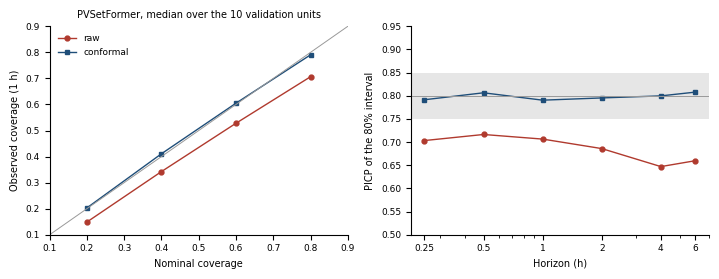

In [5]:
import matplotlib.pyplot as plt
A._style()
f8, ax = plt.subplots(1, 2, figsize=(7.2, 2.8))
nom = np.array([0.2, 0.4, 0.6, 0.8])
for kind, c, mk in [('raw', '#b03a2e', 'o'), ('conformal', '#1f4e79', 's')]:
    r = vm[(vm.window == 'full') & (vm.kind == kind) & (vm.h == C.PRIMARY_HORIZON)].iloc[0]
    ax[0].plot(nom, [r['cover20'], r['cover40'], r['cover60'], r['cover80']], marker=mk, ms=3.5, color=c, lw=1, label=kind)
    z = vm[(vm.window == 'full') & (vm.kind == kind)].set_index('h').loc[FC.H, 'cover80']
    ax[1].plot(np.array(FC.H) * 0.25, z, marker=mk, ms=3.5, color=c, lw=1, label=kind)
ax[0].plot([0, 1], [0, 1], color='0.6', lw=0.7); ax[0].set_xlim(0.1, 0.9); ax[0].set_ylim(0.1, 0.9)
ax[0].set_xlabel('Nominal coverage'); ax[0].set_ylabel('Observed coverage (1 h)'); ax[0].legend(frameon=False)
ax[1].axhspan(0.75, 0.85, color='0.9', lw=0); ax[1].axhline(0.8, color='0.6', lw=0.7)
ax[1].set_xscale('log'); ax[1].set_xticks(np.array(FC.H) * 0.25); ax[1].set_xticklabels(['0.25', '0.5', '1', '2', '4', '6'])
ax[1].set_xlabel('Horizon (h)'); ax[1].set_ylabel('PICP of the 80% interval'); ax[1].set_ylim(0.5, 0.95)
ax[0].set_title('PVSetFormer, median over the 10 validation units', fontsize=7); f8.tight_layout()

## Outputs (all-or-nothing); PVSetFormer's conformal settings join the frozen part 2

In [6]:
conf_cfg = {'part': '2b', 'model': 'PVSetFormer', 'part2c_sha256': r1['part2c_sha256'], 'variant': VAR,
            'seeds': P2C['seeds'], 'method': 'CQR (Romano et al. 2019), split conformal',
            'calibration_set': 'pseudo cold starts of the event donors; 5-seed ensemble of the early-stopped PVSetFormer predictions on the last 20% of the training issue times',
            'donors': 'clean metadata (G1/G2 target) or all (G0 target); leave-one-out prior and uncertainty set',
            'intervals': FC.PAIR_NAMES, 'normalisation': 'Gt(t + h)', 'per': 'event, origin, horizon',
            'min_scores': FC.MIN_CAL, 'power_bounds': list(FC.POWER_BOUNDS), 'median_and_point': 'unchanged',
            'keep_rule': 'median PICP80 at 1 h closer to 0.80 and median IS80 at 1 h not higher (validation units)',
            'kept': KEEP}
CONF_TEXT = yaml.safe_dump(conf_cfg, sort_keys=True)
CONF_HASH = hashlib.sha256(CONF_TEXT.encode()).hexdigest()
full = vm[vm.window == 'full']
summary = {'notebook': 'NB5c_conformal', 'environment': A.versions(), 'runtime_s': round(time.time() - t0, 1),
           'part2c_sha256': r1['part2c_sha256'], 'variant': VAR, 'conformal_config_sha256': CONF_HASH, 'kept': KEEP,
           'raw_picp80_check_max_abs_diff': CHK, 'groups_without_correction': int((corrs.n_scores < FC.MIN_CAL).sum()),
           'n_groups': len(corrs),
           'units_lower_is80_1h': int((won['conformal'] < won['raw']).sum()),
           'median_corrections_by_h': corrs.groupby('h')[[f'corr{n}' for n in FC.PAIR_NAMES]].median().round(4).to_dict('index'),
           'pseudo_raw_cover80_by_h': corrs.groupby('h')['raw_cover80'].median().round(4).to_dict(),
           **{f'{kind}_{met}_by_h': full[full.kind == kind].set_index('h')[met].round(4).to_dict()
              for kind in ['raw', 'conformal'] for met in ['cover80', 'cover60', 'cover40', 'cover20', 'PINAW', 'IS80', 'CRPS_q']}}
out = A.write_outputs('nb5c_conformal', {'corrections': corrs, 'val_conformal_scores': vs, 'val_conformal_medians': vm},
                      summary, {'fig_conformal_reliability_pvsf': f8}, parquet={'calibration_quantiles_ens': cal},
                      texts={'conformal_config_part2b_pvsf.yaml': CONF_TEXT})
print('conformal config (part 2b, PVSetFormer) sha256:', CONF_HASH)
print('written to', out, '|', sorted(x.name for x in out.iterdir()))

conformal config (part 2b, PVSetFormer) sha256: 2b171cf0954d0cd855d432fa644bacaf7f002a1a49ae15bad6d62583a8f8fdf2
written to C:\Users\Dell\Desktop\phd_ehtp\pv paper\results\nb5c_conformal | ['calibration_quantiles_ens.parquet', 'conformal_config_part2b_pvsf.yaml', 'corrections.csv', 'figures', 'summary.json', 'val_conformal_medians.csv', 'val_conformal_scores.csv']
